In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load all five datasets
flows = pd.read_csv("flows.csv")
hosts = pd.read_csv("hosts.csv")
sessions = pd.read_csv("sessions.csv")
labels = pd.read_csv("labels.csv")
calendar = pd.read_csv("calendar.csv")

print("All datasets loaded successfully!\n")

print("Flows:", flows.shape)
print("Hosts:", hosts.shape)
print("Sessions:", sessions.shape)
print("Labels:", labels.shape)
print("Calendar:", calendar.shape)


All datasets loaded successfully!

Flows: (1003, 8)
Hosts: (40, 3)
Sessions: (1000, 5)
Labels: (1000, 2)
Calendar: (1000, 4)


In [3]:

datasets = {
    "Flows": flows,
    "Hosts": hosts,
    "Sessions": sessions,
    "Labels": labels,
    "Calendar": calendar
}

for name, df in datasets.items():
    print(f"\n{'=' * 50}")
    print(f"{name.upper()} DATASET")
    print("=" * 50)
    print("Columns:", df.columns.tolist())
    print("\nFirst 5 records:")
    display(df.head())



FLOWS DATASET
Columns: ['flow_id', 'timestamp', 'src_host_id', 'dst_host_id', 'protocol', 'duration', 'bytes', 'packets']

First 5 records:


,flow_id,timestamp,src_host_id,dst_host_id,protocol,duration,bytes,packets
0,F00001,2026-01-01 00:00:00,H040,H024,TCP,15.62,141607,160
1,F00002,2026-01-01 01:00:00,H027,H020,ICMP,36.94,2794,228
2,F00003,2026-01-01 02:00:00,H017,H034,ICMP,47.89,2294,449
3,F00004,2026-01-01 03:00:00,H017,H022,UDP,26.06,544,212
4,F00005,2026-01-01 04:00:00,H017,H021,ICMP,61.75,252,215



HOSTS DATASET
Columns: ['host_id', 'host_group', 'network_zone']

First 5 records:


,host_id,host_group,network_zone
0,H001,Guest,Internal
1,H002,Servers,DMZ
2,H003,Guest,DMZ
3,H004,IoT,Internal
4,H005,Workstations,DMZ



SESSIONS DATASET
Columns: ['flow_id', 'source_zone', 'destination_zone', 'destination_port', 'port_category']

First 5 records:


,flow_id,source_zone,destination_zone,destination_port,port_category
0,F00001,DMZ,External,5432,Other
1,F00002,Internal,External,22,Other
2,F00003,Internal,Internal,80,Web (80/443)
3,F00004,Internal,DMZ,22,Web (80/443)
4,F00005,Internal,Internal,3306,Database



LABELS DATASET
Columns: ['flow_id', 'label']

First 5 records:


,flow_id,label
0,F00001,unusual
1,F00002,normal
2,F00003,normal
3,F00004,normal
4,F00005,normal



CALENDAR DATASET
Columns: ['timestamp', 'hour', 'weekday', 'maintenance_window']

First 5 records:


,timestamp,hour,weekday,maintenance_window
0,2026-01-01 00:00:00,0,Thursday,No
1,2026-01-01 01:00:00,1,Thursday,No
2,2026-01-01 02:00:00,2,Thursday,Yes
3,2026-01-01 03:00:00,3,Thursday,Yes
4,2026-01-01 04:00:00,4,Thursday,No


In [5]:


for name, df in datasets.items():
    print(f"\n{'=' * 55}")
    print(f"{name.upper()} - DATA QUALITY REPORT")
    print("=" * 55)

    print("\n1. Data types:")
    print(df.dtypes)

    print("\n2. Missing values:")
    print(df.isnull().sum())

    print("\n3. Duplicate rows:")
    print(df.duplicated().sum())

    if "flow_id" in df.columns:
        print("\n4. Duplicate flow IDs:")
        print(df["flow_id"].duplicated().sum())



FLOWS - DATA QUALITY REPORT

1. Data types:
flow_id         object
timestamp       object
src_host_id     object
dst_host_id     object
protocol        object
duration       float64
bytes            int64
packets          int64
dtype: object

2. Missing values:
flow_id         0
timestamp       0
src_host_id     0
dst_host_id     0
protocol       35
duration        0
bytes           0
packets         0
dtype: int64

3. Duplicate rows:
3

4. Duplicate flow IDs:
3

HOSTS - DATA QUALITY REPORT

1. Data types:
host_id         object
host_group      object
network_zone    object
dtype: object

2. Missing values:
host_id         0
host_group      0
network_zone    0
dtype: int64

3. Duplicate rows:
0

SESSIONS - DATA QUALITY REPORT

1. Data types:
flow_id             object
source_zone         object
destination_zone    object
destination_port     int64
port_category       object
dtype: object

2. Missing values:
flow_id             0
source_zone         0
destination_zone    0
destination_

In [6]:

print(flows["bytes"].describe())
print(flows["duration"].describe())
print(flows["packets"].describe())

Q1 = flows["bytes"].quantile(0.25)
Q3 = flows["bytes"].quantile(0.75)
IQR = Q3 - Q1

upper_limit = Q3 + 1.5 * IQR
extreme_bytes = flows[flows["bytes"] > upper_limit]

print("Upper limit:", round(upper_limit, 2))
print("Extreme records:", len(extreme_bytes))
display(extreme_bytes.head())

print(labels["label"].value_counts(dropna=False))


count    1.003000e+03
mean     2.303529e+04
std      1.364367e+05
min      5.800000e+01
25%      1.611000e+03
50%      4.136000e+03
75%      1.180600e+04
max      3.170566e+06
Name: bytes, dtype: float64
count    1003.000000
mean       34.466999
std        34.443794
min         0.020000
25%        11.000000
50%        24.840000
75%        46.425000
max       270.690000
Name: duration, dtype: float64
count    1003.000000
mean      226.130608
std       130.140596
min         1.000000
25%       112.500000
50%       226.000000
75%       340.000000
max       449.000000
Name: packets, dtype: float64
Upper limit: 27098.5
Extreme records: 125


,flow_id,timestamp,src_host_id,dst_host_id,protocol,duration,bytes,packets
0,F00001,2026-01-01 00:00:00,H040,H024,TCP,15.62,141607,160
13,F00014,2026-01-01 13:00:00,H029,H008,TCP,2.22,61390,229
31,F00032,2026-01-02 07:00:00,H026,H012,TCP,103.40,29252,420
32,F00033,2026-01-02 08:00:00,H025,H007,UDP,16.86,123552,71
44,F00045,2026-01-02 20:00:00,H019,H027,TCP,9.17,311450,30


label
normal     924
unusual     64
UNUSUAL      2
Unusual      2
NORMAL       2
normal       2
Normal       2
event        2
Name: count, dtype: int64


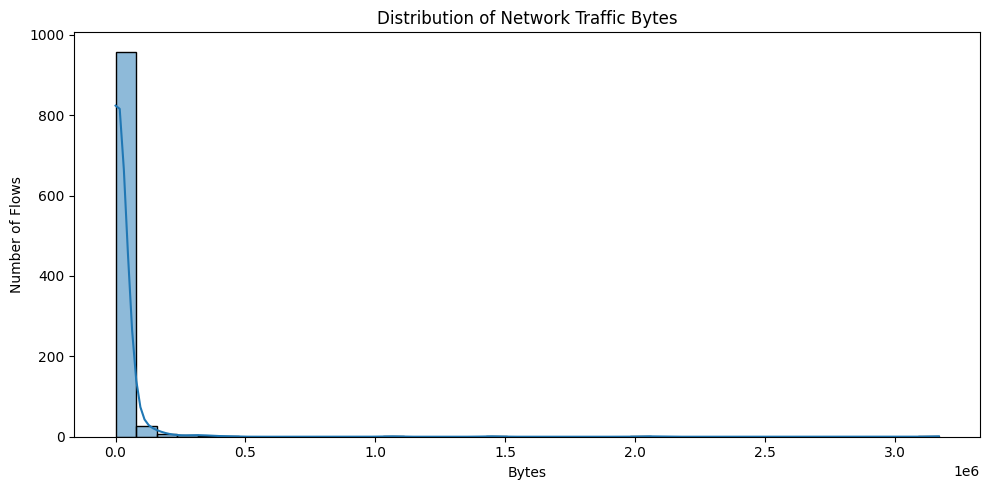

In [7]:

plt.figure(figsize=(10, 5))
sns.histplot(data=flows, x="bytes", bins=40, kde=True)
plt.title("Distribution of Network Traffic Bytes")
plt.xlabel("Bytes")
plt.ylabel("Number of Flows")
plt.tight_layout()
plt.show()


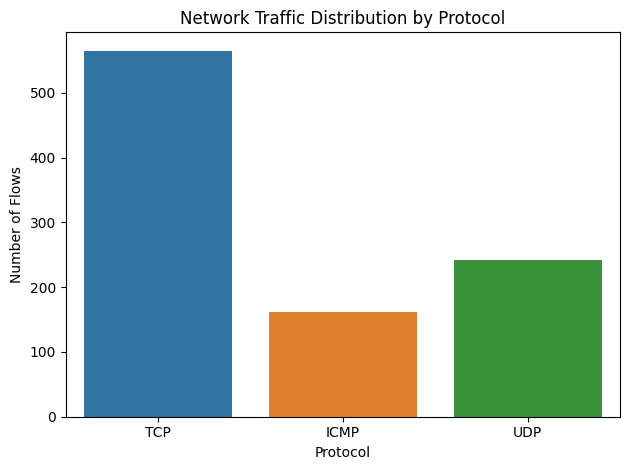

In [8]:

sns.countplot(data=flows, x="protocol", hue="protocol", legend=False)
plt.title("Network Traffic Distribution by Protocol")
plt.xlabel("Protocol")
plt.ylabel("Number of Flows")
plt.tight_layout()
plt.show()


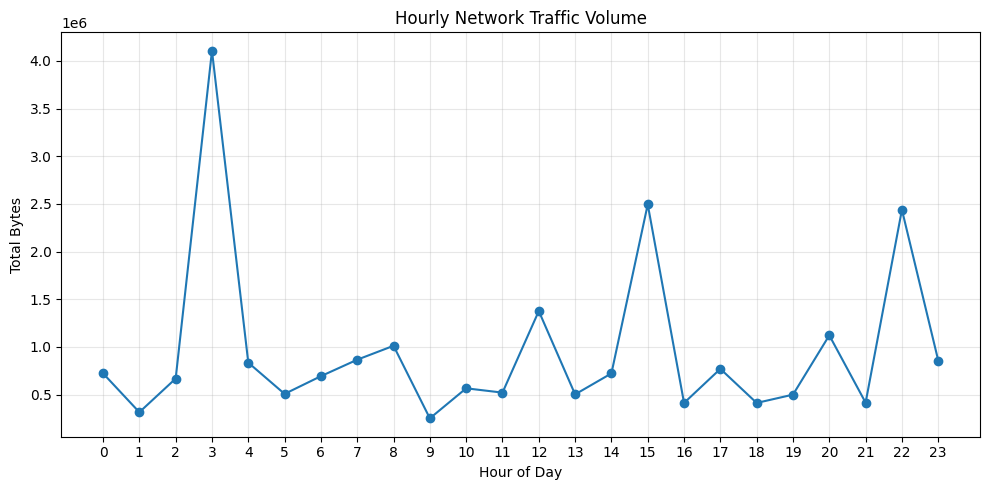

In [9]:

flows["timestamp"] = pd.to_datetime(flows["timestamp"])
flows["hour"] = flows["timestamp"].dt.hour

hourly_traffic = flows.groupby("hour")["bytes"].sum()

plt.figure(figsize=(10, 5))
hourly_traffic.plot(kind="line", marker="o")
plt.title("Hourly Network Traffic Volume")
plt.xlabel("Hour of Day")
plt.ylabel("Total Bytes")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [10]:

analysis_df = flows.merge(labels, on="flow_id", how="left")

analysis_df["label"] = (
    analysis_df["label"]
    .astype("string")
    .str.strip()
    .str.lower()
    .replace({"event": "unusual"})
)

display(
    analysis_df.groupby("label")[
        ["bytes", "duration", "packets"]
    ].mean().round(2)
)


,bytes,duration,packets
label,,,
normal,9481.43,34.42,226.67
unusual,200953.61,35.03,219.01


,total_flows,total_bytes,average_bytes
network_zone,,,
DMZ,332,11688357,35205.89
External,22,156380,7108.18
Internal,646,11211686,17355.55


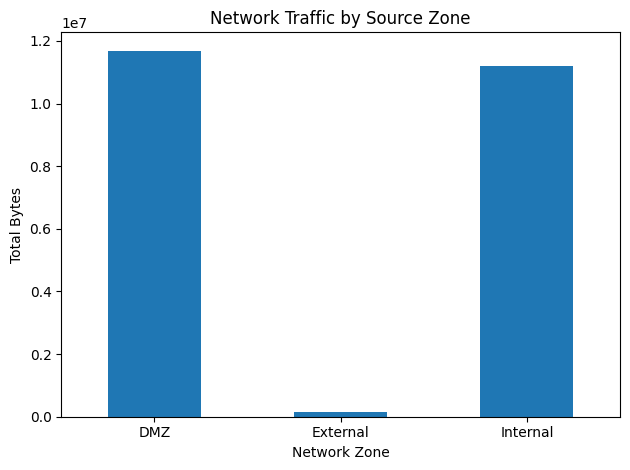

In [11]:

zone_df = flows.merge(
    hosts[["host_id", "network_zone", "host_group"]],
    left_on="src_host_id",
    right_on="host_id",
    how="left"
)

zone_summary = zone_df.groupby("network_zone").agg(
    total_flows=("flow_id", "count"),
    total_bytes=("bytes", "sum"),
    average_bytes=("bytes", "mean")
).round(2)

display(zone_summary)

zone_summary["total_bytes"].plot(kind="bar")
plt.title("Network Traffic by Source Zone")
plt.xlabel("Network Zone")
plt.ylabel("Total Bytes")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


,total_flows,total_bytes
port_category,,
Web (80/443),352,10445588
Other,234,4293856
DNS (53),122,1867906
SSH (22),120,1141923
Database,98,1207410
Mail (25/587),77,4147714


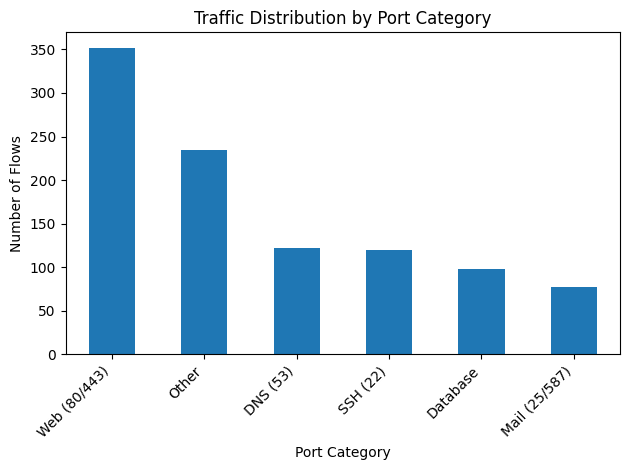

In [13]:

port_df = flows.merge(
    sessions[["flow_id", "destination_port", "port_category"]],
    on="flow_id",
    how="left"
)

port_summary = port_df.groupby("port_category").agg(
    total_flows=("flow_id", "count"),
    total_bytes=("bytes", "sum")
).sort_values("total_flows", ascending=False)

display(port_summary)

port_summary["total_flows"].plot(kind="bar")
plt.title("Traffic Distribution by Port Category")
plt.xlabel("Port Category")
plt.ylabel("Number of Flows")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


,alert_count,total_bytes
host_group,,
Workstations,25,5245661
Servers,17,1755296
Guest,17,5927638
IoT,8,650078
Admin,4,689033


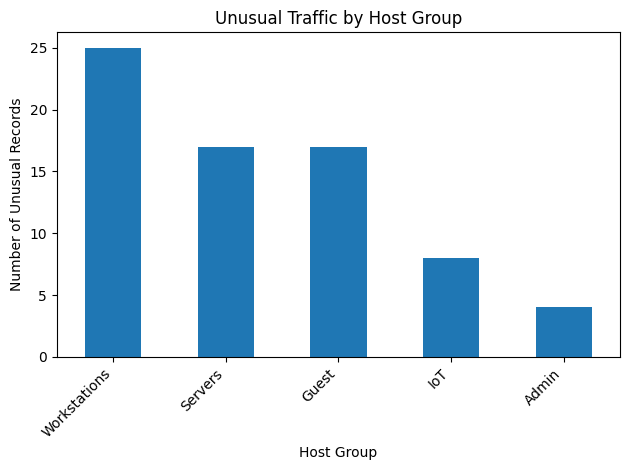

In [14]:

host_df = flows.merge(
    hosts[["host_id", "host_group"]],
    left_on="src_host_id",
    right_on="host_id",
    how="left"
)

host_df = host_df.merge(
    labels[["flow_id", "label"]],
    on="flow_id",
    how="left"
)

host_df["label"] = (
    host_df["label"]
    .astype("string")
    .str.strip()
    .str.lower()
    .replace({"event": "unusual"})
)

alert_summary = host_df[
    host_df["label"].isin(["unusual", "event"])
].groupby("host_group").agg(
    alert_count=("flow_id", "count"),
    total_bytes=("bytes", "sum")
).sort_values("alert_count", ascending=False)

display(alert_summary)

alert_summary["alert_count"].plot(kind="bar")
plt.title("Unusual Traffic by Host Group")
plt.xlabel("Host Group")
plt.ylabel("Number of Unusual Records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [15]:

print("Rows before cleaning:", len(flows))
print("Duplicate flow IDs:", flows["flow_id"].duplicated().sum())

flows = flows.drop_duplicates(
    subset="flow_id",
    keep="first"
).copy()

print("Rows after cleaning:", len(flows))
print("Remaining duplicate IDs:", flows["flow_id"].duplicated().sum())


Rows before cleaning: 1003
Duplicate flow IDs: 3
Rows after cleaning: 1000
Remaining duplicate IDs: 0


In [16]:

print("Missing protocols before:", flows["protocol"].isnull().sum())

flows["protocol"] = flows["protocol"].fillna("Unknown")

print("Missing protocols after:", flows["protocol"].isnull().sum())
print(flows["protocol"].value_counts())


Missing protocols before: 35
Missing protocols after: 0
protocol
TCP        563
UDP        241
ICMP       161
Unknown     35
Name: count, dtype: int64


In [17]:

labels["label"] = (
    labels["label"]
    .astype("string")
    .str.strip()
    .str.lower()
    .replace({
        "event": "unusual",
        "normal": "normal",
        "unusual": "unusual"
    })
)

print(labels["label"].value_counts(dropna=False))


label
normal     930
unusual     70
Name: count, dtype: Int64


In [18]:

Q1 = flows["bytes"].quantile(0.25)
Q3 = flows["bytes"].quantile(0.75)
IQR = Q3 - Q1

upper = Q3 + 1.5 * IQR

print("Extreme byte records:", (flows["bytes"] > upper).sum())


Extreme byte records: 124


In [19]:

valid_hosts = hosts["host_id"]

unmatched = ~flows["src_host_id"].isin(valid_hosts)

print("Unmatched host records:", unmatched.sum())

flows.loc[unmatched, "src_host_id"] = "Unknown"


Unmatched host records: 3


In [21]:

calendar["timestamp"] = pd.to_datetime(calendar["timestamp"])

df = flows.merge(hosts, left_on="src_host_id", right_on="host_id", how="left")
df = df.merge(sessions, on="flow_id", how="left")
df = df.merge(labels, on="flow_id", how="left")
df = df.merge(calendar, on="timestamp", how="left")

print(df.shape)
display(df.head())



(1000, 20)


,flow_id,timestamp,src_host_id,dst_host_id,protocol,duration,bytes,packets,hour_x,host_id,host_group,network_zone,source_zone,destination_zone,destination_port,port_category,label,hour_y,weekday,maintenance_window
0,F00001,2026-01-01 00:00:00,H040,H024,TCP,15.62,141607,160,0,H040,IoT,DMZ,DMZ,External,5432,Other,unusual,0,Thursday,No
1,F00002,2026-01-01 01:00:00,H027,H020,ICMP,36.94,2794,228,1,H027,Servers,Internal,Internal,External,22,Other,normal,1,Thursday,No
2,F00003,2026-01-01 02:00:00,H017,H034,ICMP,47.89,2294,449,2,H017,Servers,Internal,Internal,Internal,80,Web (80/443),normal,2,Thursday,Yes
3,F00004,2026-01-01 03:00:00,H017,H022,UDP,26.06,544,212,3,H017,Servers,Internal,Internal,DMZ,22,Web (80/443),normal,3,Thursday,Yes
4,F00005,2026-01-01 04:00:00,H017,H021,ICMP,61.75,252,215,4,H017,Servers,Internal,Internal,Internal,3306,Database,normal,4,Thursday,No


In [22]:

print("Dataset shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print("Missing values:")
print(df.isnull().sum())


Dataset shape: (1000, 20)
Duplicate rows: 0
Missing values:
flow_id               0
timestamp             0
src_host_id           0
dst_host_id           0
protocol              0
duration              0
bytes                 0
packets               0
hour_x                0
host_id               3
host_group            3
network_zone          3
source_zone           0
destination_zone      0
destination_port      0
port_category         0
label                 0
hour_y                0
weekday               0
maintenance_window    0
dtype: int64


In [23]:

df.to_csv("cleaned_traffic.csv", index=False)

print("Cleaned dataset saved successfully!")


Cleaned dataset saved successfully!


In [24]:

df["timestamp"] = pd.to_datetime(df["timestamp"])

df["hour"] = df["timestamp"].dt.hour
df["day_of_week"] = df["timestamp"].dt.day_name()
df["bytes_per_packet"] = df["bytes"] / df["packets"]

display(df[["timestamp", "hour", "day_of_week", "bytes_per_packet"]].head())


,timestamp,hour,day_of_week,bytes_per_packet
0,2026-01-01 00:00:00,0,Thursday,885.043750
1,2026-01-01 01:00:00,1,Thursday,12.254386
2,2026-01-01 02:00:00,2,Thursday,5.109131
3,2026-01-01 03:00:00,3,Thursday,2.566038
4,2026-01-01 04:00:00,4,Thursday,1.172093


In [25]:

df["protocol_encoded"] = df["protocol"].astype("category").cat.codes
df["zone_encoded"] = df["network_zone"].astype("category").cat.codes

display(df[["protocol", "protocol_encoded", "network_zone", "zone_encoded"]].head())


,protocol,protocol_encoded,network_zone,zone_encoded
0,TCP,1,DMZ,0
1,ICMP,0,Internal,2
2,ICMP,0,Internal,2
3,UDP,2,Internal,2
4,ICMP,0,Internal,2


In [26]:

features = df[["duration", "bytes", "packets", "hour", "bytes_per_packet"]]

display(features.corr().round(2))


,duration,bytes,packets,hour,bytes_per_packet
duration,1.00,-0.01,-0.03,0.00,-0.01
bytes,-0.01,1.00,0.02,0.00,0.48
packets,-0.03,0.02,1.00,0.04,-0.19
hour,0.00,0.00,0.04,1.00,-0.01
bytes_per_packet,-0.01,0.48,-0.19,-0.01,1.00


In [27]:

df.to_csv("cleaned_traffic.csv", index=False)

print("Final dataset saved!")
print("Rows:", len(df))
print("Columns:", len(df.columns))


Final dataset saved!
Rows: 1000
Columns: 25


In [28]:

summary = df.groupby("protocol").agg(
    total_flows=("flow_id", "count"),
    total_bytes=("bytes", "sum"),
    average_duration=("duration", "mean")
).round(2)

display(summary)

summary.to_csv("protocol_summary.csv")
print("Protocol summary saved!")


,total_flows,total_bytes,average_duration
protocol,,,
ICMP,161,1992122,35.75
TCP,563,11757970,33.77
UDP,241,8756887,34.41
Unknown,35,510714,39.27


Protocol summary saved!


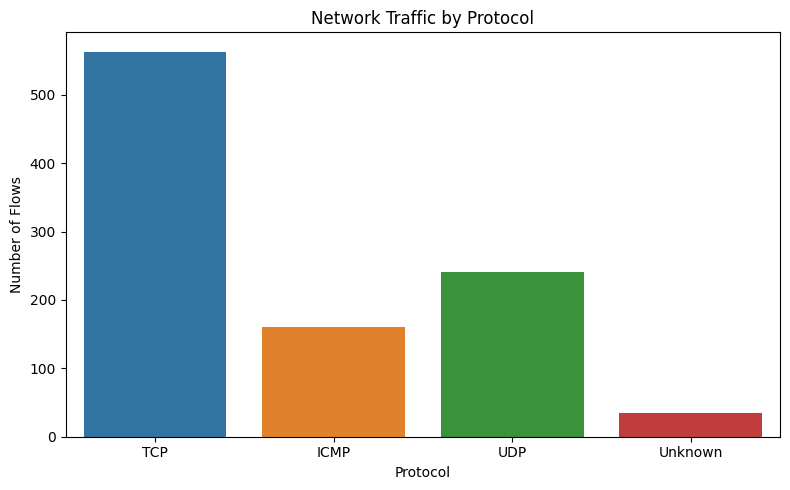

In [29]:

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="protocol", hue="protocol", legend=False)
plt.title("Network Traffic by Protocol")
plt.xlabel("Protocol")
plt.ylabel("Number of Flows")
plt.tight_layout()
plt.savefig("protocol_distribution.png", dpi=300)
plt.show()


In [30]:

df.to_csv("final_traffic_dataset.csv", index=False)

print("Final dataset exported successfully!")
print("Total records:", len(df))
print("Total features:", len(df.columns))



Final dataset exported successfully!
Total records: 1000
Total features: 25


In [31]:

import os

for file in os.listdir():
    if file.endswith((".csv", ".png")):
        print(file)


protocol_summary.csv
labels.csv
sessions.csv
protocol_distribution.png
calendar.csv
final_traffic_dataset.csv
hosts.csv
cleaned_traffic.csv
flows.csv
